# Credit Card Fraud Detection
Dataset: `mlg-ulb/creditcardfraud` (284,807 transactions, 492 frauds ≈ 0.17%).

Because of the extreme imbalance, accuracy is meaningless. Primary metric: **PR-AUC (average precision)**, plus precision/recall at a tuned threshold.

## 1. Setup & data

In [17]:
import kagglehub, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
df = pd.read_csv(os.path.join(path, "creditcard.csv"))
print(df.shape)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. EDA

0 missing values; 1081 duplicate rows
Class
0    284315
1       492
Name: count, dtype: int64 
Fraud rate: 0.1727%


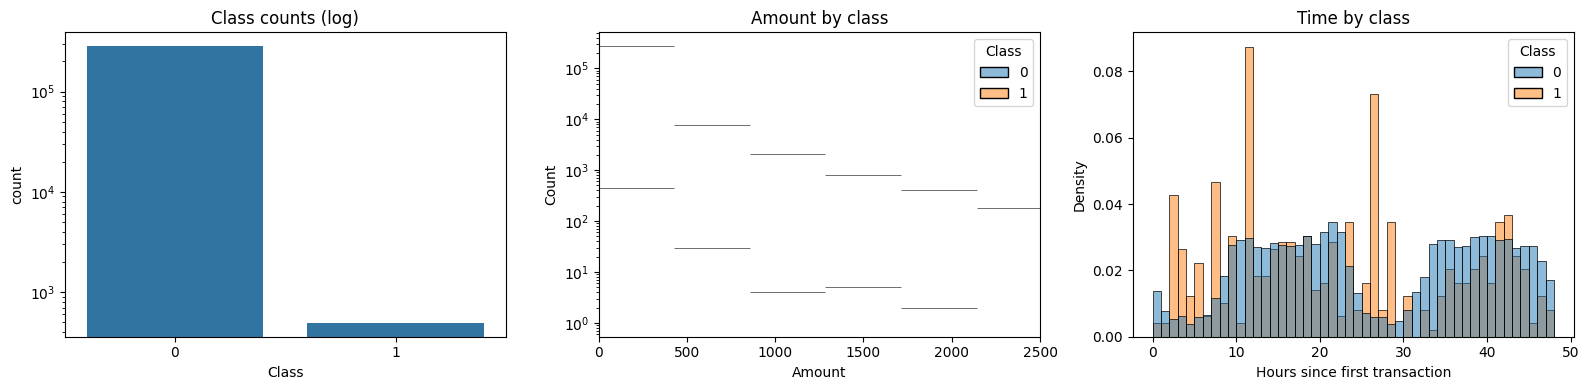

In [18]:
print(df.isna().sum().sum(), "missing values;", df.duplicated().sum(), "duplicate rows")
counts = df["Class"].value_counts()
print(counts, f"\nFraud rate: {counts[1]/len(df):.4%}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="Class", data=df, ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Class counts (log)")
sns.histplot(data=df, x="Amount", hue="Class", bins=60, log_scale=(False, True), ax=ax[1], common_norm=False)
ax[1].set_xlim(0, 2500); ax[1].set_title("Amount by class")
sns.histplot(data=df, x=df["Time"]/3600, hue="Class", bins=48, stat="density", common_norm=False, ax=ax[2])
ax[2].set_xlabel("Hours since first transaction"); ax[2].set_title("Time by class")
plt.tight_layout(); plt.show()

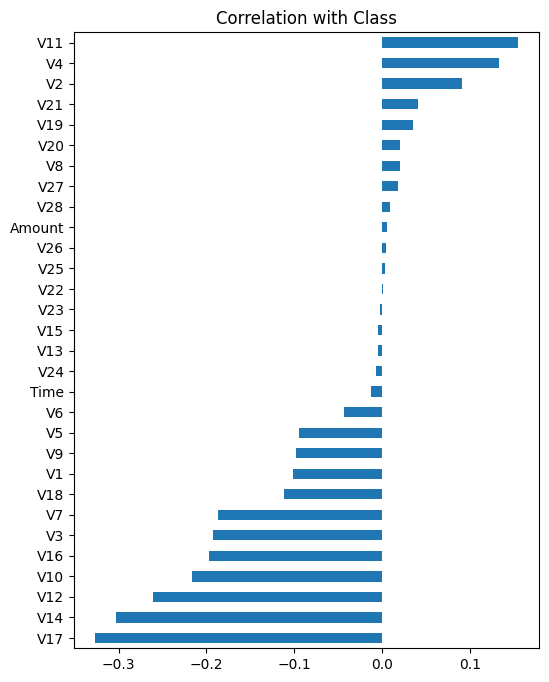

In [19]:
# Which PCA components separate fraud best?
corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="barh", figsize=(6, 8), title="Correlation with Class"); plt.show()

## 3. Clean and split
Remove duplicate rows first (identical rows could end up in both train and test), then split. The test set is **not touched** until the single final evaluation in section 6.

In [20]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape, f"fraud rate: {df['Class'].mean():.4%}")

from sklearn.model_selection import train_test_split
X = df.drop(columns="Class"); y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, y_train.sum(), "frauds in train,", y_test.sum(), "in test")

(283726, 31) fraud rate: 0.1667%
(226980, 30) (56746, 30) 378 frauds in train, 95 in test


## 4. Models as pipelines
`V1–V28` are already PCA-transformed. Only `Amount` and `Time` are scaled, and the scaler lives **inside** each pipeline, so during cross-validation it is re-fit on each training fold only (no leakage).

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def make_pre():
    return ColumnTransformer([("scale", RobustScaler(), ["Amount", "Time"])],
                             remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")

spw = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                           n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=spw, eval_metric="aucpr", n_jobs=-1, random_state=SEED),
}
pipes = {name: Pipeline([("pre", make_pre()), ("model", m)]) for name, m in models.items()}

## 5. Model selection: 5-fold CV on the training set only
The best model is chosen from cross-validation scores, not from the test set. (This cell takes a few minutes.)

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in pipes.items():
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    rows.append({"model": name, "CV PR-AUC": s.mean(), "std": s.std()})
cv_table = pd.DataFrame(rows).set_index("model").sort_values("CV PR-AUC", ascending=False)
display(cv_table.round(4))
best = cv_table.index[0]
print("Selected model:", best)

,CV PR-AUC,std
model,,
XGBoost,0.8533,0.0286
RandomForest,0.8411,0.0358
LogReg,0.7544,0.0265


Selected model: XGBoost


## 6. Threshold from out-of-fold predictions, then ONE test evaluation

Threshold chosen on training data: 0.969
Test PR-AUC: 0.8277 | ROC-AUC: 0.9772
              precision    recall  f1-score   support

           0     0.9996    1.0000    0.9998     56651
           1     0.9861    0.7474    0.8503        95

    accuracy                         0.9996     56746
   macro avg     0.9928    0.8737    0.9250     56746
weighted avg     0.9996    0.9996    0.9995     56746



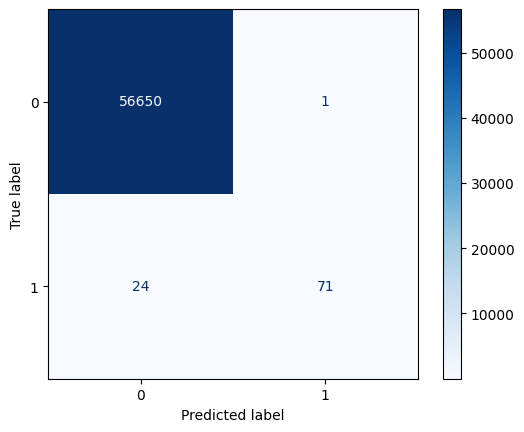

In [23]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# 1) choose the threshold using out-of-fold predictions on the TRAINING set
oof = cross_val_predict(pipes[best], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
pr, rc, th = precision_recall_curve(y_train, oof)
f1 = 2*pr[:-1]*rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
t = th[f1.argmax()]
print(f"Threshold chosen on training data: {t:.3f}")

# 2) fit on the full training set and evaluate once on the untouched test set
final = pipes[best].fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
print(f"Test PR-AUC: {average_precision_score(y_test, p_test):.4f} | ROC-AUC: {roc_auc_score(y_test, p_test):.4f}")
pred = (p_test >= t).astype(int)
print(classification_report(y_test, pred, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap="Blues"); plt.show()

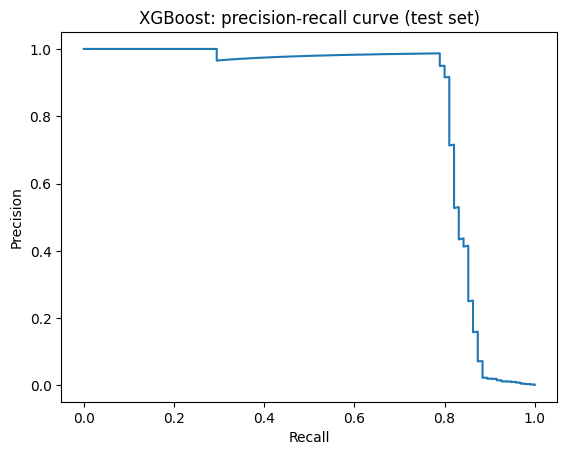

In [24]:
pr_t, rc_t, _ = precision_recall_curve(y_test, p_test)
plt.plot(rc_t, pr_t); plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"{best}: precision-recall curve (test set)"); plt.show()

## 7. Feature importance

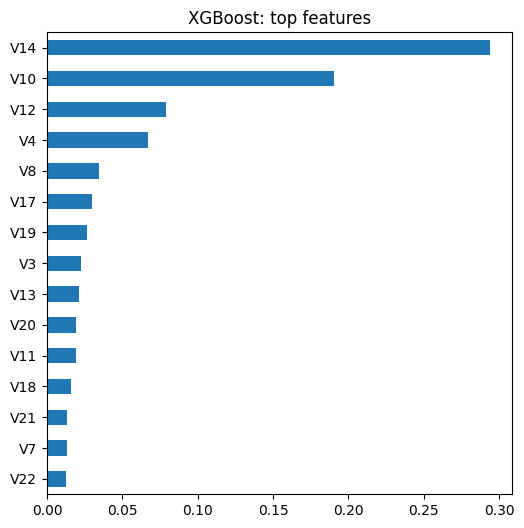

In [25]:
names = final[:-1].get_feature_names_out()
mdl = final.named_steps["model"]
imp = getattr(mdl, "feature_importances_", None)
if imp is None: imp = np.abs(mdl.coef_[0])
pd.Series(imp, index=names).sort_values().tail(15).plot(kind="barh", figsize=(6, 6), title=f"{best}: top features"); plt.show()

## 8. Neural network (PyTorch MLP)
Same train/test split. A validation set is carved out of the **training** data for early stopping and the threshold, so the test set stays untouched. The loss uses a positive-class weight to handle the imbalance.

In [26]:
import torch, torch.nn as nn
torch.manual_seed(SEED)

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
pre = make_pre().fit(X_tr)                       # scaler fit on the training part only
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Xtr_t, Xval_t, Xte_t = (to_t(pre.transform(d)) for d in (X_tr, X_val, X_test))
ytr_t = to_t(y_tr.values).unsqueeze(1)

net = nn.Sequential(nn.Linear(Xtr_t.shape[1], 64), nn.ReLU(), nn.Dropout(0.2),
                    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
                    nn.Linear(32, 1))
# softened class weight (square root of the imbalance ratio): the full ratio makes training unstable
pos_w = torch.tensor([((y_tr == 0).sum() / (y_tr == 1).sum()) ** 0.5], dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

def predict(X):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(X)).squeeze(1).numpy()

best_ap, best_state, patience, bad = 0.0, None, 6, 0
for epoch in range(40):
    net.train()
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 1024):
        idx = perm[i:i + 1024]
        opt.zero_grad(); loss_fn(net(Xtr_t[idx]), ytr_t[idx]).backward(); opt.step()
    ap = average_precision_score(y_val, predict(Xval_t))
    if ap > best_ap:
        best_ap, bad = ap, 0
        best_state = {k: v.clone() for k, v in net.state_dict().items()}
    else:
        bad += 1
        if bad >= patience: break
    if epoch % 5 == 0: print(f"epoch {epoch:2d} | val PR-AUC {ap:.4f}")
net.load_state_dict(best_state)
print(f"Best validation PR-AUC: {best_ap:.4f} (stopped at epoch {epoch})")

epoch  0 | val PR-AUC 0.7631
epoch  5 | val PR-AUC 0.8045
epoch 10 | val PR-AUC 0.8331
epoch 15 | val PR-AUC 0.8553
epoch 20 | val PR-AUC 0.8688
epoch 25 | val PR-AUC 0.8776
Best validation PR-AUC: 0.8782 (stopped at epoch 27)


In [27]:
# threshold from the validation set, then evaluate once on the test set
pr, rc, th = precision_recall_curve(y_val, predict(Xval_t))
f1 = 2*pr[:-1]*rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
t_nn = th[f1.argmax()]
p_nn = predict(Xte_t)
print(f"MLP test PR-AUC: {average_precision_score(y_test, p_nn):.4f} | ROC-AUC: {roc_auc_score(y_test, p_nn):.4f}")
print(classification_report(y_test, (p_nn >= t_nn).astype(int), digits=4))

pd.DataFrame({"model": [best, "MLP (PyTorch)"],
              "test PR-AUC": [average_precision_score(y_test, p_test), average_precision_score(y_test, p_nn)]}).round(4)

MLP test PR-AUC: 0.7611 | ROC-AUC: 0.9511
              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     56651
           1     0.8471    0.7579    0.8000        95

    accuracy                         0.9994     56746
   macro avg     0.9233    0.8788    0.8998     56746
weighted avg     0.9993    0.9994    0.9993     56746



,model,test PR-AUC
0,XGBoost,0.8277
1,MLP (PyTorch),0.7611


## Notes
- The test set was used once, for the final report. Model choice and both thresholds came from training data only.
- With only ~95 frauds in the test set, small differences between models are noise; compare the CV standard deviations.
- Next ideas: SMOTE inside an `imblearn` pipeline, SHAP explanations, a time-based split (train on earlier hours, test on later), and a threshold based on business cost (missed fraud vs. false alarm).